# Interpretable Credit Default Risk and Model Validation

This project develops and validates an interpretable credit-default risk model
using the UCI *Default of Credit Card Clients* dataset. It compares logistic
regression with XGBoost, selects a cost-sensitive decision threshold using
out-of-fold predictions, evaluates the final model on an untouched holdout
set, and audits calibration, explainability, and subgroup performance.

**Validation design.** All exploratory analysis, feature design,
hyperparameter selection, and threshold selection use only the development
(training) sample. The test sample is reserved for one final performance
assessment. The false-negative and false-positive costs used here are
illustrative rather than institution-specific loss estimates.


## 1. Data Loading and Variable Definition

The dataset contains 30,000 credit-card customers, 23 predictor variables,
and a binary target indicating default in the following month. Run this
notebook with the project's virtual-environment kernel.


In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# 下载并读取UCI编号350的信用卡违约数据集
credit = fetch_ucirepo(id=350)

# X：用于预测的客户特征
X = credit.data.features.copy()

# y：我们要预测的结果，即客户下个月是否违约
y = credit.data.targets.copy()

print("X的形状：", X.shape)
print("y的形状：", y.shape)

display(X.head())
display(y.head())

X的形状： (30000, 23)
y的形状： (30000, 1)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


,Y
0,1
1,1
2,0
3,0
4,0


In [2]:
# 六个月份：从最近的9月到更早的4月
months = ["sep", "aug", "jul", "jun", "may", "apr"]

# 为23个特征准备清晰的英文名称
feature_names = (
    [
        "credit_limit",       # 信用额度
        "sex",                # 性别
        "education",          # 教育程度
        "marital_status",     # 婚姻状况
        "age"                 # 年龄
    ]
    + [f"repayment_status_{month}" for month in months]
    + [f"bill_amount_{month}" for month in months]
    + [f"payment_amount_{month}" for month in months]
)

# 复制X并替换列名
X_named = X.copy()
X_named.columns = feature_names

# 将Y从二维表格转换成一列，并改名
y_named = y.iloc[:, 0].rename("default_next_month")

# 把特征和预测目标合并
df = pd.concat([X_named, y_named], axis=1)

# 增加客户编号
df.insert(0, "customer_id", range(1, len(df) + 1))

print("完整数据形状：", df.shape)
display(df.head())

完整数据形状： (30000, 25)


,customer_id,credit_limit,sex,education,marital_status,age,repayment_status_sep,repayment_status_aug,repayment_status_jul,repayment_status_jun,...,bill_amount_jun,bill_amount_may,bill_amount_apr,payment_amount_sep,payment_amount_aug,payment_amount_jul,payment_amount_jun,payment_amount_may,payment_amount_apr,default_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Data Quality and Cleaning

The checks below cover class balance, missing values, duplicate identifiers,
category codes, and numerical plausibility. Education codes 0, 5, and 6 are
combined into `Other/Unknown`, while marital-status code 0 is combined with
the existing `Other` category according to the dataset documentation.


In [3]:
# 分别统计0和1的客户数量
target_counts = (
    df["default_next_month"]
    .value_counts()
    .reindex([0, 1])
)

# 计算相应比例
target_rates = (
    df["default_next_month"]
    .value_counts(normalize=True)
    .reindex([0, 1])
    * 100
)

target_summary = pd.DataFrame({
    "客户数量": target_counts,
    "占比（%）": target_rates.round(2)
})

target_summary.index = ["0 = 未违约", "1 = 违约"]

display(target_summary)

# 假设模型将所有客户都预测成未违约
baseline_accuracy = target_counts.loc[0] / len(df)

print(f"全部预测为未违约时，准确率也能达到：{baseline_accuracy:.2%}")

,客户数量,占比（%）
0 = 未违约,23364,77.88
1 = 违约,6636,22.12


全部预测为未违约时，准确率也能达到：77.88%


In [4]:
# 1. 检查缺失值
print("缺失值总数：", df.isna().sum().sum())

# 2. 检查客户编号是否重复
print("重复的客户编号数量：", df["customer_id"].duplicated().sum())

# 3. 排除人为创建的customer_id后，检查业务数据是否完全重复
duplicate_records = df.drop(columns=["customer_id"]).duplicated().sum()
print("除customer_id外，完全重复的记录数量：", duplicate_records)

# 4. 检查几个类别变量出现了哪些编码
category_columns = ["sex", "education", "marital_status"]

for column in category_columns:
    print(f"\n{column}的取值及数量：")
    print(df[column].value_counts().sort_index())

# 5. 检查六个月的还款状态中出现了哪些编码
repayment_columns = [
    "repayment_status_sep",
    "repayment_status_aug",
    "repayment_status_jul",
    "repayment_status_jun",
    "repayment_status_may",
    "repayment_status_apr"
]

repayment_values = sorted(
    set(df[repayment_columns].to_numpy().ravel())
)

print("\n还款状态出现的全部编码：")
print(repayment_values)

缺失值总数： 0
重复的客户编号数量： 0
除customer_id外，完全重复的记录数量： 35

sex的取值及数量：
sex
1    11888
2    18112
Name: count, dtype: int64

education的取值及数量：
education
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

marital_status的取值及数量：
marital_status
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

还款状态出现的全部编码：
[np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [5]:
# 保留原始df，创建一个清洗版本
df_clean = df.copy()

# education:
# 1=研究生，2=大学，3=高中，4=其他/未知
df_clean["education"] = (
    df_clean["education"]
    .replace({
        0: 4,
        5: 4,
        6: 4
    })
)

# marital_status:
# 1=已婚，2=单身，3=其他/未知
df_clean["marital_status"] = (
    df_clean["marital_status"]
    .replace({
        0: 3
    })
)

print("清洗后的education：")
print(df_clean["education"].value_counts().sort_index())

print("\n清洗后的marital_status：")
print(df_clean["marital_status"].value_counts().sort_index())

print("\n清洗后数据形状：", df_clean.shape)

清洗后的education：
education
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64

清洗后的marital_status：
marital_status
1    13659
2    15964
3      377
Name: count, dtype: int64

清洗后数据形状： (30000, 25)


**Duplicate-record decision.** The 35 identical observed profiles are retained.
Customer identifiers are unique, and different customers can share the same
recorded characteristics. Removing these rows solely because their observed
profiles match could discard valid customers.


In [6]:
# 6个月的账单金额列
bill_columns = [
    "bill_amount_sep",
    "bill_amount_aug",
    "bill_amount_jul",
    "bill_amount_jun",
    "bill_amount_may",
    "bill_amount_apr"
]

# 6个月的实际还款金额列
payment_columns = [
    "payment_amount_sep",
    "payment_amount_aug",
    "payment_amount_jul",
    "payment_amount_jun",
    "payment_amount_may",
    "payment_amount_apr"
]

# 需要检查的数值变量
numeric_columns = (
    ["credit_limit", "age"]
    + bill_columns
    + payment_columns
)

# 查看基本统计量
numeric_summary = (
    df_clean[numeric_columns]
    .describe()
    .T[["min", "25%", "50%", "mean", "75%", "max"]]
)

display(numeric_summary)

print("信用额度小于或等于0的客户数：",
      (df_clean["credit_limit"] <= 0).sum())

print("年龄小于18岁的客户数：",
      (df_clean["age"] < 18).sum())

print("年龄大于100岁的客户数：",
      (df_clean["age"] > 100).sum())

print("负数账单单元格数量：",
      (df_clean[bill_columns] < 0).sum().sum())

print("至少有一个月负数账单的客户数：",
      (df_clean[bill_columns] < 0).any(axis=1).sum())

print("负数还款单元格数量：",
      (df_clean[payment_columns] < 0).sum().sum())

,min,25%,50%,mean,75%,max
credit_limit,10000.0,50000.00,140000.0,167484.322667,240000.00,1000000.0
age,21.0,28.00,34.0,35.485500,41.00,79.0
bill_amount_sep,-165580.0,3558.75,22381.5,51223.330900,67091.00,964511.0
bill_amount_aug,-69777.0,2984.75,21200.0,49179.075167,64006.25,983931.0
bill_amount_jul,-157264.0,2666.25,20088.5,47013.154800,60164.75,1664089.0
bill_amount_jun,-170000.0,2326.75,19052.0,43262.948967,54506.00,891586.0
bill_amount_may,-81334.0,1763.00,18104.5,40311.400967,50190.50,927171.0
bill_amount_apr,-339603.0,1256.00,17071.0,38871.760400,49198.25,961664.0
payment_amount_sep,0.0,1000.00,2100.0,5663.580500,5006.00,873552.0
payment_amount_aug,0.0,833.00,2009.0,5921.163500,5000.00,1684259.0


信用额度小于或等于0的客户数： 0
年龄小于18岁的客户数： 0
年龄大于100岁的客户数： 0
负数账单单元格数量： 3932
至少有一个月负数账单的客户数： 1930
负数还款单元格数量： 0


## 3. Train–Test Split

An 80/20 stratified split preserves the default rate in both samples. The
holdout test set is not used for exploratory analysis, feature development,
hyperparameter tuning, or threshold selection.


In [7]:
from sklearn.model_selection import train_test_split

# customer_id只是编号，不能用来预测
X_model = df_clean.drop(
    columns=["customer_id", "default_next_month"]
)

# 需要预测的目标：1代表下个月违约，0代表未违约
y_model = df_clean["default_next_month"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,       # 20%留作最终测试
    random_state=42,      # 确保每次运行得到相同结果
    stratify=y_model      # 保持训练集和测试集的违约率一致
)

split_summary = pd.DataFrame(
    {
        "样本数量": [len(y_train), len(y_test)],
        "违约客户数": [y_train.sum(), y_test.sum()],
        "违约率": [y_train.mean(), y_test.mean()]
    },
    index=["训练集", "测试集"]
)

split_summary["违约率"] = split_summary["违约率"].map("{:.2%}".format)

display(split_summary)
print("X_train形状：", X_train.shape)
print("X_test形状：", X_test.shape)

,样本数量,违约客户数,违约率
训练集,24000,5309,22.12%
测试集,6000,1327,22.12%


X_train形状： (24000, 23)
X_test形状： (6000, 23)


## 4. Exploratory Data Analysis

### 4.1 Default Rate by Latest Repayment Status

Business question: Does recent payment delinquency indicate a higher probability of default in the following month?

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 把训练特征和训练标签临时合并，方便做探索性分析
train_df = X_train.copy()
train_df["default_next_month"] = y_train

# 按最近一期（9月）还款状态分组
status_summary = (
    train_df
    .groupby("repayment_status_sep")["default_next_month"]
    .agg(
        customer_count="size",
        default_count="sum",
        default_rate="mean"
    )
    .reset_index()
    .sort_values("repayment_status_sep")
)

# 将违约率转换成百分比
status_summary["default_rate_pct"] = (
    status_summary["default_rate"] * 100
).round(2)

display(
    status_summary[
        [
            "repayment_status_sep",
            "customer_count",
            "default_count",
            "default_rate_pct"
        ]
    ]
)

,repayment_status_sep,customer_count,default_count,default_rate_pct
0,-2,2198,279,12.69
1,-1,4527,753,16.63
2,0,11781,1508,12.80
3,1,3000,1031,34.37
4,2,2138,1483,69.36
5,3,245,188,76.73
6,4,58,38,65.52
7,5,18,8,44.44
8,6,10,6,60.00
9,7,9,7,77.78


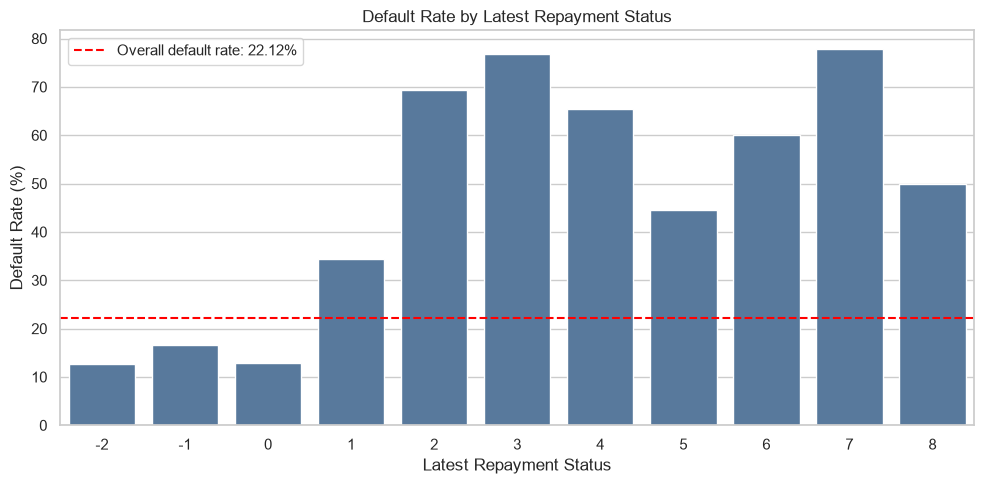

In [9]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=status_summary,
    x="repayment_status_sep",
    y="default_rate_pct",
    color="#4C78A8"
)

# 红色虚线代表训练集整体违约率22.12%
plt.axhline(
    y=y_train.mean() * 100,
    color="red",
    linestyle="--",
    label=f"Overall default rate: {y_train.mean():.2%}"
)

plt.xlabel("Latest Repayment Status")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Latest Repayment Status")
plt.legend()
plt.tight_layout()
plt.show()

**Finding.** Customers with a positive repayment-status code had a
substantially higher default rate than customers with codes of zero or
below. The default rate increased from 12.80% for status 0 to 34.37%
for status 1 and 69.36% for status 2.

Rates for the most severe status codes were not strictly monotonic
because these categories contained very few customers. Therefore,
high-severity categories should not be interpreted independently
without considering their sample sizes.

### 4.2 Default Rate by Number of Delinquent Months

Business question: Does repeated delinquency indicate a higher risk
than a single month of delinquency?

In [10]:
repayment_status_columns = [
    "repayment_status_sep",
    "repayment_status_aug",
    "repayment_status_jul",
    "repayment_status_jun",
    "repayment_status_may",
    "repayment_status_apr"
]

# 单独建立EDA数据，避免改动原始训练数据
train_eda = train_df.copy()

# 状态大于0代表该月存在明确逾期
# True会被当作1，False会被当作0
train_eda["delinquent_months"] = (
    train_eda[repayment_status_columns]
    .gt(0)
    .sum(axis=1)
)

delinquency_summary = (
    train_eda
    .groupby("delinquent_months")["default_next_month"]
    .agg(
        customer_count="size",
        default_count="sum",
        default_rate="mean"
    )
    .reset_index()
)

delinquency_summary["default_rate_pct"] = (
    delinquency_summary["default_rate"] * 100
).round(2)

display(
    delinquency_summary[
        [
            "delinquent_months",
            "customer_count",
            "default_count",
            "default_rate_pct"
        ]
    ]
)

,delinquent_months,customer_count,default_count,default_rate_pct
0,0,15896,1830,11.51
1,1,3572,1070,29.96
2,2,1532,612,39.95
3,3,936,471,50.32
4,4,767,445,58.02
5,5,237,142,59.92
6,6,1060,739,69.72


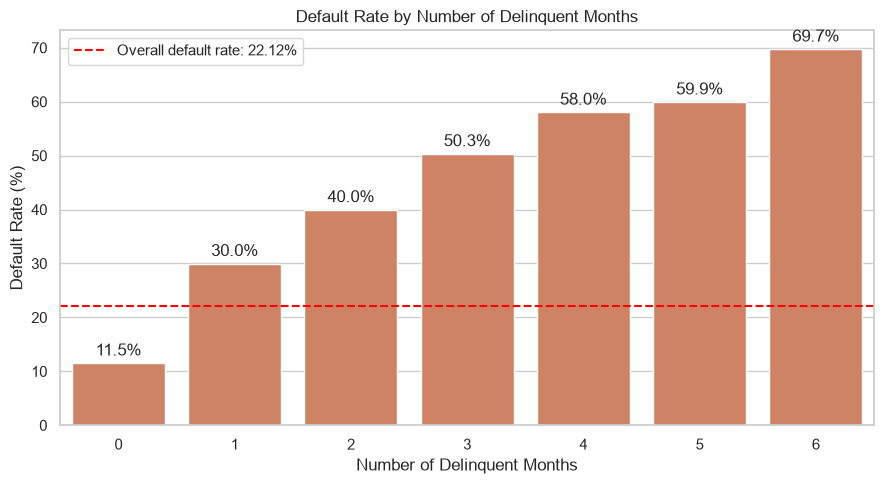

In [11]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=delinquency_summary,
    x="delinquent_months",
    y="default_rate_pct",
    color="#E07B54"
)

plt.axhline(
    y=y_train.mean() * 100,
    color="red",
    linestyle="--",
    label=f"Overall default rate: {y_train.mean():.2%}"
)

plt.xlabel("Number of Delinquent Months")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Number of Delinquent Months")

# 在柱子上显示百分比
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.legend()
plt.tight_layout()
plt.show()

**Finding.** Default risk increased consistently with the persistence
of delinquency. Customers with no delinquent months had an 11.51%
default rate, while customers delinquent in all six months had a
69.72% default rate.

This suggests that delinquency persistence contains additional risk
information beyond the latest repayment status. Therefore, the number
of delinquent months will be retained as an engineered feature.

### 4.3 Default Rate by Credit Utilization

Business question: Are customers using a larger proportion of their
credit limit more likely to default?

In [12]:
import numpy as np

# 最近一期账单金额 ÷ 信用额度
train_eda["credit_utilization_sep"] = (
    train_eda["bill_amount_sep"]
    / train_eda["credit_limit"]
)

# 使用固定的业务区间，避免根据结果随意划分
utilization_bins = [
    -np.inf, 0, 0.25, 0.50, 0.75, 1.00, np.inf
]

utilization_labels = [
    "Below 0",
    "0–25%",
    "25–50%",
    "50–75%",
    "75–100%",
    "100%+"
]

train_eda["utilization_band_sep"] = pd.cut(
    train_eda["credit_utilization_sep"],
    bins=utilization_bins,
    labels=utilization_labels,
    right=False
)

utilization_summary = (
    train_eda
    .groupby(
        "utilization_band_sep",
        observed=True
    )["default_next_month"]
    .agg(
        customer_count="size",
        default_count="sum",
        default_rate="mean"
    )
    .reset_index()
)

utilization_summary["default_rate_pct"] = (
    utilization_summary["default_rate"] * 100
).round(2)

display(
    utilization_summary[
        [
            "utilization_band_sep",
            "customer_count",
            "default_count",
            "default_rate_pct"
        ]
    ]
)

,utilization_band_sep,customer_count,default_count,default_rate_pct
0,Below 0,468,82,17.52
1,0–25%,10748,1950,18.14
2,25–50%,2885,636,22.05
3,50–75%,2869,733,25.55
4,75–100%,5342,1388,25.98
5,100%+,1688,520,30.81


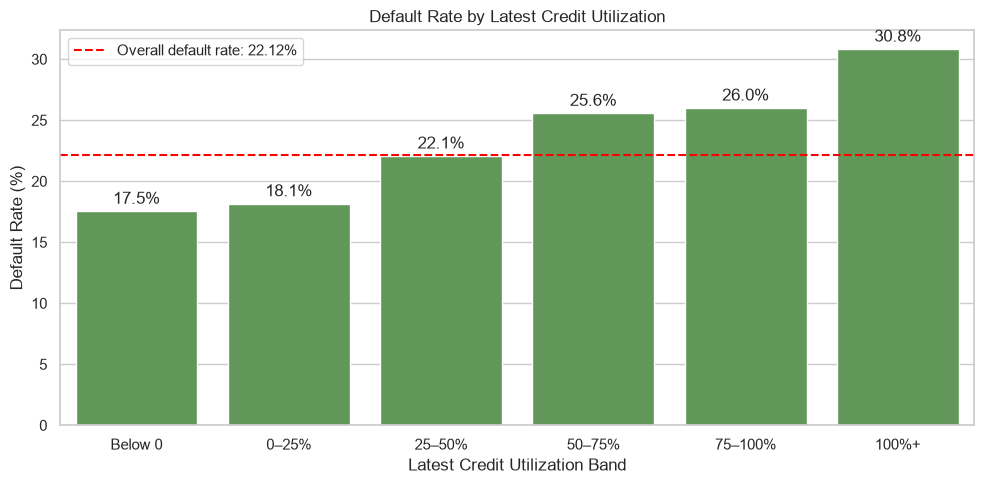

In [13]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=utilization_summary,
    x="utilization_band_sep",
    y="default_rate_pct",
    color="#59A14F"
)

plt.axhline(
    y=y_train.mean() * 100,
    color="red",
    linestyle="--",
    label=f"Overall default rate: {y_train.mean():.2%}"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.xlabel("Latest Credit Utilization Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Latest Credit Utilization")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Behavioural Feature Engineering

Five transparent behavioural variables summarize delinquency persistence,
maximum delinquency severity, and credit utilization. Feature engineering is
implemented as a deterministic function and is applied identically to the
training and test samples.


In [14]:
# 六个月的账单金额列
bill_columns = [
    "bill_amount_sep",
    "bill_amount_aug",
    "bill_amount_jul",
    "bill_amount_jun",
    "bill_amount_may",
    "bill_amount_apr"
]

# 六个月的还款状态列
repayment_status_columns = [
    "repayment_status_sep",
    "repayment_status_aug",
    "repayment_status_jul",
    "repayment_status_jun",
    "repayment_status_may",
    "repayment_status_apr"
]

In [15]:
def add_behavior_features(data):
    # 复制一份数据，避免修改原始数据
    result = data.copy()

    # 特征1：过去六个月发生过逾期的月份数
    result["delinquent_months"] = (
        result[repayment_status_columns]
        .gt(0)
        .sum(axis=1)
    )

    # 特征2：过去六个月最严重的逾期程度
    result["max_delinquency"] = (
        result[repayment_status_columns]
        .clip(lower=0)
        .max(axis=1)
    )

    # 特征3：最近一期信用额度使用率
    result["latest_utilization"] = (
        result["bill_amount_sep"]
        / result["credit_limit"]
    )

    # 特征4：六个月平均信用额度使用率
    result["average_utilization"] = (
        result[bill_columns].mean(axis=1)
        / result["credit_limit"]
    )

    # 特征5：六个月最高信用额度使用率
    result["maximum_utilization"] = (
        result[bill_columns].max(axis=1)
        / result["credit_limit"]
    )

    return result

In [16]:
X_train_fe = add_behavior_features(X_train)
X_test_fe = add_behavior_features(X_test)

print("原始训练集形状：", X_train.shape)
print("特征工程后训练集形状：", X_train_fe.shape)

print("原始测试集形状：", X_test.shape)
print("特征工程后测试集形状：", X_test_fe.shape)

原始训练集形状： (24000, 23)
特征工程后训练集形状： (24000, 28)
原始测试集形状： (6000, 23)
特征工程后测试集形状： (6000, 28)


In [17]:
engineered_features = [
    "delinquent_months",
    "max_delinquency",
    "latest_utilization",
    "average_utilization",
    "maximum_utilization"
]

display(
    X_train_fe[engineered_features]
    .describe()
    .T[["min", "25%", "50%", "mean", "75%", "max"]]
)

,min,25%,50%,mean,75%,max
delinquent_months,0.000000,0.000000,0.000000,0.835708,1.000000,6.000000
max_delinquency,0.000000,0.000000,0.000000,0.682875,2.000000,8.000000
latest_utilization,-0.619892,0.021788,0.314936,0.423342,0.828832,6.455300
average_utilization,-0.232590,0.030303,0.284231,0.372191,0.685880,5.364308
maximum_utilization,-0.100000,0.071571,0.429782,0.494305,0.921900,10.688575


In [18]:
utilization_features = [
    "latest_utilization",
    "average_utilization",
    "maximum_utilization"
]

# 查看更详细的分位数
percentile_summary = (
    X_train_fe[utilization_features]
    .quantile([0.01, 0.05, 0.50, 0.95, 0.99, 1.00])
    .T
)

percentile_summary.columns = [
    "1%",
    "5%",
    "50%",
    "95%",
    "99%",
    "100%"
]

display(percentile_summary)

,1%,5%,50%,95%,99%,100%
latest_utilization,-0.000484,0.000000,0.314936,1.012805,1.233520,6.455300
average_utilization,0.000000,0.000995,0.284231,0.959034,1.048061,5.364308
maximum_utilization,0.000000,0.003225,0.429782,1.033013,1.565131,10.688575


In [19]:
extreme_count_summary = pd.DataFrame({
    "小于0": (X_train_fe[utilization_features] < 0).sum(),
    "超过100%": (X_train_fe[utilization_features] > 1).sum(),
    "超过200%": (X_train_fe[utilization_features] > 2).sum(),
    "超过300%": (X_train_fe[utilization_features] > 3).sum()
})

display(extreme_count_summary)

,小于0,超过100%,超过200%,超过300%
latest_utilization,468,1685,27,8
average_utilization,153,507,10,1
maximum_utilization,66,3129,45,10


## 6. Logistic Regression Baseline

A logistic regression model is used as an interpretable baseline.
Model performance is estimated using five-fold stratified
cross-validation on the training set. The held-out test set remains
untouched.

In [20]:
# 这些变量的数字实际代表类别，而不是连续数值
categorical_features = [
    "sex",
    "education",
    "marital_status",
    "repayment_status_sep",
    "repayment_status_aug",
    "repayment_status_jul",
    "repayment_status_jun",
    "repayment_status_may",
    "repayment_status_apr"
]

# 除上述类别变量外，其余变量作为数值变量
numeric_features = [
    column
    for column in X_train_fe.columns
    if column not in categorical_features
]

print("类别变量数量：", len(categorical_features))
print("数值变量数量：", len(numeric_features))
print("总变量数量：", len(categorical_features) + len(numeric_features))

类别变量数量： 9
数值变量数量： 19
总变量数量： 28


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 数值变量：使用RobustScaler缩放
numeric_pipeline = Pipeline([
    ("scaler", RobustScaler())
])

# 类别变量：转换成One-Hot编码
categorical_pipeline = Pipeline([
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore")
    )
])

# 根据变量类型采用不同处理方法
preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

# 将预处理和逻辑回归连接成完整流程
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=3000,
            solver="liblinear",
            random_state=42
        )
    )
])

print("逻辑回归Pipeline建立完成")

逻辑回归Pipeline建立完成


In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall"
}

cv_results = cross_validate(
    logistic_model,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "平均值": {
        metric: cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "标准差": {
        metric: cv_results[f"test_{metric}"].std()
        for metric in scoring
    }
})

display(cv_summary.round(4))

,平均值,标准差
roc_auc,0.7726,0.0057
pr_auc,0.5430,0.0132
accuracy,0.8213,0.0021
balanced_accuracy,0.6562,0.0019
precision,0.6827,0.0160
recall,0.3601,0.0066


### 6.1 Effect of Feature Engineering

Two logistic regression models are compared under the same
cross-validation procedure. The only difference is whether the five
engineered behavioural features are included.

In [23]:
# 原始23个变量中的数值变量
raw_numeric_features = [
    column
    for column in X_train.columns
    if column not in categorical_features
]

print("原始类别变量数量：", len(categorical_features))
print("原始数值变量数量：", len(raw_numeric_features))
print("原始变量总数：",
      len(categorical_features) + len(raw_numeric_features))

原始类别变量数量： 9
原始数值变量数量： 14
原始变量总数： 23


In [24]:
raw_preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("scaler", RobustScaler())
        ]),
        raw_numeric_features
    ),
    (
        "categorical",
        Pipeline([
            (
                "onehot",
                OneHotEncoder(handle_unknown="ignore")
            )
        ]),
        categorical_features
    )
])

raw_logistic_model = Pipeline([
    ("preprocessor", raw_preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=3000,
            solver="liblinear",
            random_state=42
        )
    )
])

In [25]:
raw_cv_results = cross_validate(
    raw_logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [26]:
metric_names = list(scoring.keys())

model_comparison = pd.DataFrame({
    "Raw Features": [
        raw_cv_results[f"test_{metric}"].mean()
        for metric in metric_names
    ],
    "Engineered Features": [
        cv_results[f"test_{metric}"].mean()
        for metric in metric_names
    ]
}, index=metric_names)

model_comparison["Difference"] = (
    model_comparison["Engineered Features"]
    - model_comparison["Raw Features"]
)

display(model_comparison.round(4))

,Raw Features,Engineered Features,Difference
roc_auc,0.7690,0.7726,0.0036
pr_auc,0.5432,0.5430,-0.0002
accuracy,0.8202,0.8213,0.0011
balanced_accuracy,0.6545,0.6562,0.0017
precision,0.6783,0.6827,0.0044
recall,0.3573,0.3601,0.0028


**Finding.** Feature engineering produced a modest improvement in
ROC-AUC from 0.7690 to 0.7726, while PR-AUC remained effectively
unchanged. The engineered features therefore provided limited
incremental predictive information because much of the same
information was already present in the original monthly variables.

Nevertheless, the engineered features were retained because they
provide clearer business interpretation and may help nonlinear models.

## 7. XGBoost Model

XGBoost is evaluated as a nonlinear challenger model using the same
five-fold stratified cross-validation procedure.

In [27]:
from xgboost import XGBClassifier

tree_preprocessor = ColumnTransformer(
    [
        (
            "numeric",
            "passthrough",
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    sparse_threshold=1.0
)

In [28]:
xgb_classifier = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

xgb_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", xgb_classifier)
])

In [29]:
xgb_cv_results = cross_validate(
    xgb_model,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [30]:

xgb_summary = pd.DataFrame({
    "平均值": {
        metric: xgb_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "标准差": {
        metric: xgb_cv_results[f"test_{metric}"].std()
        for metric in scoring
    }
})

display(xgb_summary.round(4))

,平均值,标准差
roc_auc,0.7866,0.0051
pr_auc,0.5606,0.0095
accuracy,0.8212,0.0034
balanced_accuracy,0.6602,0.0040
precision,0.6739,0.0167
recall,0.3716,0.0060


In [31]:
model_comparison_2 = pd.DataFrame({
    "Logistic Regression": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "XGBoost": [
        xgb_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ]
}, index=scoring.keys())

model_comparison_2["XGBoost Difference"] = (
    model_comparison_2["XGBoost"]
    - model_comparison_2["Logistic Regression"]
)

display(model_comparison_2.round(4))

,Logistic Regression,XGBoost,XGBoost Difference
roc_auc,0.7726,0.7866,0.0140
pr_auc,0.5430,0.5606,0.0176
accuracy,0.8213,0.8212,-0.0002
balanced_accuracy,0.6562,0.6602,0.0040
precision,0.6827,0.6739,-0.0089
recall,0.3601,0.3716,0.0115


**Finding.** XGBoost outperformed logistic regression in both ROC-AUC
(0.7866 versus 0.7726) and PR-AUC (0.5606 versus 0.5430), indicating
better ranking performance and stronger identification of default
customers.

At the default 0.5 threshold, XGBoost achieved slightly higher recall
but slightly lower precision. Because classification performance
depends on the decision threshold, threshold selection will be
performed separately using business costs.

XGBoost is selected as the primary model, while logistic regression is
retained as an interpretable benchmark.

### 7.1 Hyperparameter Tuning

Randomized search is conducted on the training data to identify an
improved XGBoost configuration. Average precision is used as the
optimization metric because the default class is the minority class.

In [32]:
from sklearn.model_selection import RandomizedSearchCV

parameter_space = {
    "model__n_estimators": [200, 300, 400, 500],
    "model__learning_rate": [0.02, 0.05, 0.08, 0.10],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__gamma": [0, 0.1, 0.3, 0.5],
    "model__reg_lambda": [1, 3, 5, 10]
}

tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=parameter_space,
    n_iter=20,
    scoring="average_precision",
    cv=tuning_cv,
    refit=True,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

In [33]:
# Assign the fitted search object to suppress Jupyter's estimator diagram.
# This avoids a Windows/GBK display error without affecting model fitting.
_ = random_search.fit(X_train_fe, y_train)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [34]:
print(
    "最佳交叉验证PR-AUC：",
    round(random_search.best_score_, 4)
)

print("\n最佳参数：")

for parameter, value in random_search.best_params_.items():
    print(parameter, "=", value)

tuned_xgb_model = random_search.best_estimator_

print("\n最佳模型已成功保存")

最佳交叉验证PR-AUC： 0.5624

最佳参数：
model__subsample = 0.7
model__reg_lambda = 10
model__n_estimators = 300
model__min_child_weight = 3
model__max_depth = 5
model__learning_rate = 0.02
model__gamma = 0
model__colsample_bytree = 0.7

最佳模型已成功保存


In [35]:
print(tuned_xgb_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('numeric', 'passthrough',
                                                  ['credit_limit', 'age',
                                                   'bill_amount_sep',
                                                   'bill_amount_aug',
                                                   'bill_amount_jul',
                                                   'bill_amount_jun',
                                                   'bill_amount_may',
                                                   'bill_amount_apr',
                                                   'payment_amount_sep',
                                                   'payment_amount_aug',
                                                   'payment_amount_jul',
                                                   'payment_amount_jun',
                                                

### 7.2 Evaluation of the Tuned XGBoost Model

The selected hyperparameters are evaluated using the same five-fold
cross-validation procedure as the baseline model to provide a
consistent comparison.

In [36]:
tuned_xgb_cv_results = cross_validate(
    tuned_xgb_model,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [37]:
tuning_comparison = pd.DataFrame({
    "Baseline XGBoost": [
        xgb_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Tuned XGBoost": [
        tuned_xgb_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ]
}, index=scoring.keys())

tuning_comparison["Difference"] = (
    tuning_comparison["Tuned XGBoost"]
    - tuning_comparison["Baseline XGBoost"]
)

display(tuning_comparison.round(4))

,Baseline XGBoost,Tuned XGBoost,Difference
roc_auc,0.7866,0.7878,0.0012
pr_auc,0.5606,0.5656,0.0050
accuracy,0.8212,0.8221,0.0009
balanced_accuracy,0.6602,0.6608,0.0005
precision,0.6739,0.6791,0.0052
recall,0.3716,0.3714,-0.0002


In [38]:
tuned_xgb_summary = pd.DataFrame({
    "平均值": {
        metric: tuned_xgb_cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "标准差": {
        metric: tuned_xgb_cv_results[f"test_{metric}"].std()
        for metric in scoring
    }
})

display(tuned_xgb_summary.round(4))

,平均值,标准差
roc_auc,0.7878,0.0044
pr_auc,0.5656,0.0072
accuracy,0.8221,0.0024
balanced_accuracy,0.6608,0.0020
precision,0.6791,0.0134
recall,0.3714,0.0030


**Finding.** Hyperparameter tuning improved PR-AUC from 0.5606 to
0.5656, while ROC-AUC increased slightly from 0.7866 to 0.7878.
Recall remained almost unchanged because both models were evaluated
using the default 0.5 classification threshold.

The tuned XGBoost model is selected as the final candidate model for
threshold optimization and holdout evaluation.

**Model-selection note.** Hyperparameters and the cross-validation summary
above use the same development sample. The tuned cross-validation figures are
therefore model-development estimates and may be mildly optimistic. The
untouched holdout set below remains the authoritative estimate of final model
performance.

### 7.3 Cost-Sensitive Threshold Selection

The operating threshold is selected from out-of-fold development predictions.
Each customer's probability is produced by a fold model that did not train on
that customer. The assumed cost of a false negative is five times the cost of
a false positive; this is an illustrative business assumption.


In [39]:
from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    tuned_xgb_model,
    X_train_fe,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF预测数量：", len(oof_probabilities))
print("平均预测违约概率：", round(oof_probabilities.mean(), 4))
print("最低预测概率：", round(oof_probabilities.min(), 4))
print("最高预测概率：", round(oof_probabilities.max(), 4))

OOF预测数量： 24000
平均预测违约概率： 0.2213
最低预测概率： 0.0198
最高预测概率： 0.8666


In [40]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

false_negative_cost = 5
false_positive_cost = 1

threshold_rows = []

for threshold in np.arange(0.01, 1.00, 0.01):
    threshold = round(float(threshold), 2)

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_train,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        predictions
    )

    specificity = tn / (tn + fp)

    f1 = f1_score(
        y_train,
        predictions
    )

    total_cost = (
        false_negative_cost * fn
        + false_positive_cost * fp
    )

    threshold_rows.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "predicted_high_risk_rate": predictions.mean(),
        "false_positive": fp,
        "false_negative": fn,
        "cost": total_cost
    })

threshold_results = pd.DataFrame(threshold_rows)


In [41]:
best_threshold_row = threshold_results.loc[
    threshold_results["cost"].idxmin()
]

selected_threshold = float(
    best_threshold_row["threshold"]
)

print("成本最低的阈值：", selected_threshold)
print()
display(
    best_threshold_row.to_frame(
        name="Selected Threshold"
    ).round(4)
)

成本最低的阈值： 0.19



,Selected Threshold
threshold,0.1900
precision,0.4180
recall,0.7031
specificity,0.7220
f1,0.5243
predicted_high_risk_rate,0.3721
false_positive,5197.0000
false_negative,1576.0000
cost,13077.0000


In [42]:
comparison_thresholds = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]

threshold_comparison = threshold_results[
    threshold_results["threshold"].isin(
        comparison_thresholds
    )
].copy()

display(threshold_comparison.round(4))

,threshold,precision,recall,specificity,f1,predicted_high_risk_rate,false_positive,false_negative,cost
19,0.20,0.4324,0.6820,0.7457,0.5293,0.3489,4753,1688,13193
24,0.25,0.4947,0.6118,0.8225,0.5471,0.2735,3317,2061,13622
29,0.30,0.5373,0.5579,0.8635,0.5474,0.2297,2551,2347,14286
34,0.35,0.5781,0.5080,0.8947,0.5408,0.1944,1968,2612,15028
39,0.40,0.6168,0.4536,0.9200,0.5227,0.1627,1496,2901,16001
44,0.45,0.6510,0.4101,0.9376,0.5032,0.1393,1167,3132,16827
49,0.50,0.6788,0.3714,0.9501,0.4802,0.1210,933,3337,17618


**Threshold decision.** Under the illustrative assumption that a
false negative costs five times as much as a false positive, the
cost-minimizing threshold was 0.19.

Compared with the default 0.50 threshold, recall increased from 37.14%
to 70.31%, while precision decreased from 67.88% to 41.80%. The
estimated error cost decreased by approximately 25.8%.

This threshold is conditional on the assumed cost ratio and would need
to be reconsidered if loss severity or review capacity changed.

### 7.4 Final Holdout Evaluation

The selected model is refitted on the complete development sample. The test
sample is then scored once using both the conventional 0.50 cutoff and the
pre-selected cost-sensitive threshold.


In [43]:
from sklearn.base import clone

# Clone the selected specification before the final refit so that the final
# fitted object is clearly separated from the model-selection object.
final_model = clone(tuned_xgb_model)
final_model.fit(X_train_fe, y_train)

test_probabilities = final_model.predict_proba(
    X_test_fe
)[:, 1]

test_predictions_selected = (
    test_probabilities >= selected_threshold
).astype(int)

test_predictions_default = (
    test_probabilities >= 0.50
).astype(int)


The first evaluation block reports threshold-independent ranking and
probability metrics. The following blocks compare operating thresholds and
show the selected-threshold confusion matrix.


In [44]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss
)

test_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

test_pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

test_ks = np.max(tpr - fpr)

test_brier = brier_score_loss(
    y_test,
    test_probabilities
)

ranking_results = pd.DataFrame({
    "Test Result": [
        test_roc_auc,
        test_pr_auc,
        test_ks,
        test_brier
    ]
}, index=[
    "ROC-AUC",
    "PR-AUC",
    "KS",
    "Brier Score"
])

display(ranking_results.round(4))

,Test Result
ROC-AUC,0.7835
PR-AUC,0.5621
KS,0.4341
Brier Score,0.1341


In [45]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


def evaluate_test_threshold(
    y_true,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            predictions
        ),
        "specificity": tn / (tn + fp),
        "f1": f1_score(
            y_true,
            predictions
        ),
        "high_risk_rate": predictions.mean(),
        "false_positive": fp,
        "false_negative": fn,
        "cost": fp + 5 * fn
    }

In [46]:
test_threshold_comparison = pd.DataFrame(
    [
        evaluate_test_threshold(
            y_test,
            test_probabilities,
            0.50
        ),
        evaluate_test_threshold(
            y_test,
            test_probabilities,
            selected_threshold
        )
    ],
    index=[
        "Default threshold",
        "Selected threshold"
    ]
)

display(test_threshold_comparison.round(4))

,threshold,accuracy,balanced_accuracy,precision,recall,specificity,f1,high_risk_rate,false_positive,false_negative,cost
Default threshold,0.50,0.8198,0.6572,0.6699,0.3655,0.9489,0.4729,0.1207,239,842,4449
Selected threshold,0.19,0.7125,0.7024,0.4101,0.6843,0.7205,0.5128,0.3690,1306,419,3401


In [47]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions_selected,
    labels=[0, 1]
).ravel()

test_confusion_matrix = pd.DataFrame(
    [
        [tn, fp],
        [fn, tp]
    ],
    index=[
        "Actual: Non-default",
        "Actual: Default"
    ],
    columns=[
        "Predicted: Non-default",
        "Predicted: Default"
    ]
)

display(test_confusion_matrix)

,Predicted: Non-default,Predicted: Default
Actual: Non-default,3367,1306
Actual: Default,419,908


**Holdout finding.** The final model achieved ROC-AUC 0.7835, PR-AUC
0.5621, KS 0.4341, and Brier score 0.1341 on the untouched test set. Moving
from the 0.50 cutoff to the pre-selected cost-sensitive threshold increased
recall from 36.55% to 68.43% and reduced the illustrative error cost from
4,449 to 3,401 (23.6%), while lowering precision and overall accuracy. This
trade-off is expected because more customers are sent for high-risk review.


## 8. Probability Calibration

Probability calibration evaluates whether predicted default
probabilities correspond to observed default frequencies. This is
important because credit-risk decisions rely not only on ranking
customers but also on interpreting predicted probabilities.

In [48]:
calibration_data = pd.DataFrame({
    "predicted_probability": test_probabilities,
    "actual_default": y_test.to_numpy()
})

# 按预测概率将测试客户平均分成10组
calibration_data["risk_decile"] = pd.qcut(
    calibration_data["predicted_probability"],
    q=10,
    duplicates="drop"
)

calibration_summary = (
    calibration_data
    .groupby("risk_decile", observed=True)
    .agg(
        customer_count=("actual_default", "size"),
        mean_predicted_probability=(
            "predicted_probability",
            "mean"
        ),
        observed_default_rate=(
            "actual_default",
            "mean"
        )
    )
    .reset_index()
)

calibration_summary["calibration_gap"] = (
    calibration_summary["observed_default_rate"]
    - calibration_summary["mean_predicted_probability"]
)

display(
    calibration_summary.round(4)
)


,risk_decile,customer_count,mean_predicted_probability,observed_default_rate,calibration_gap
0,"(0.0203, 0.0528]",600,0.0415,0.0417,0.0002
1,"(0.0528, 0.0748]",600,0.0642,0.0617,-0.0025
2,"(0.0748, 0.098]",600,0.0866,0.0817,-0.0049
3,"(0.098, 0.123]",600,0.1107,0.1217,0.0109
4,"(0.123, 0.147]",600,0.1348,0.1483,0.0135
5,"(0.147, 0.178]",600,0.1617,0.1850,0.0233
6,"(0.178, 0.229]",600,0.2003,0.1817,-0.0186
7,"(0.229, 0.345]",600,0.2785,0.2600,-0.0185
8,"(0.345, 0.579]",600,0.4382,0.4367,-0.0016
9,"(0.579, 0.871]",600,0.7029,0.6933,-0.0096


In [49]:
calibration_summary["absolute_gap"] = (
    calibration_summary["calibration_gap"].abs()
)

ece = (
    calibration_summary["customer_count"]
    / calibration_summary["customer_count"].sum()
    * calibration_summary["absolute_gap"]
).sum()

null_brier = (
    y_test.mean()
    * (1 - y_test.mean())
)

brier_skill_score = (
    1
    - test_brier / null_brier
)

print("Expected Calibration Error：", round(ece, 4))
print("基准模型Brier Score：", round(null_brier, 4))
print("XGBoost Brier Score：", round(test_brier, 4))
print("Brier Skill Score：", round(brier_skill_score, 4))

Expected Calibration Error： 0.0104
基准模型Brier Score： 0.1723
XGBoost Brier Score： 0.1341
Brier Skill Score： 0.2218


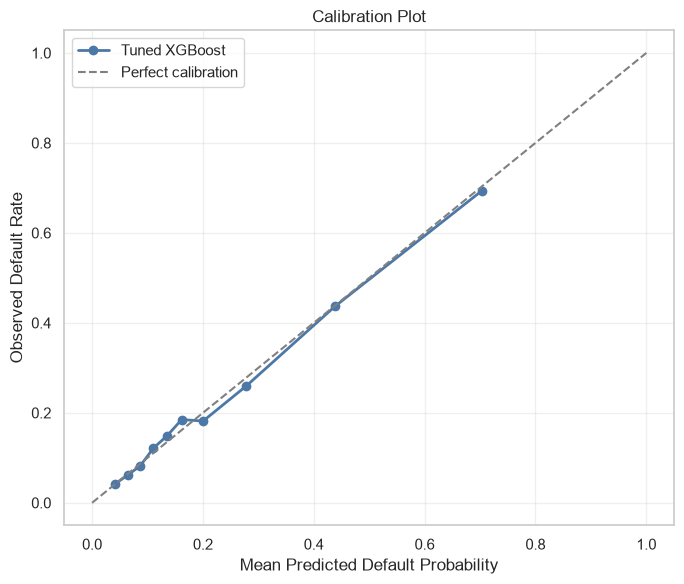

In [50]:
plt.figure(figsize=(7, 6))

plt.plot(
    calibration_summary[
        "mean_predicted_probability"
    ],
    calibration_summary[
        "observed_default_rate"
    ],
    marker="o",
    linewidth=2,
    color="#4C78A8",
    label="Tuned XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Rate")
plt.title("Calibration Plot")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
from pathlib import Path

Path("figures").mkdir(parents=True, exist_ok=True)
plt.savefig(
    "figures/calibration_plot.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


**Calibration finding.** The model demonstrated good probability
calibration, with an expected calibration error of 0.0104. Predicted
and observed default rates were closely aligned across all ten risk
groups.

The Brier score of 0.1341 was lower than the constant-probability
benchmark of 0.1723, corresponding to a Brier skill score of 0.2218.
No additional probability recalibration was applied.

## 9. Model Interpretation with SHAP

SHAP values are used to explain the contribution of each feature to
the tuned XGBoost model's predicted default risk.

In [51]:
import shap
from scipy import sparse

# Use a fixed sample for reproducible explanations.
shap_sample = X_test_fe.sample(
    n=min(2000, len(X_test_fe)),
    random_state=42
)

final_preprocessor = final_model.named_steps[
    "preprocessor"
]
final_xgb = final_model.named_steps["model"]

# Preserve the exact sparse representation used by the fitted pipeline.
shap_sample_transformed = final_preprocessor.transform(
    shap_sample
)
shap_feature_names = (
    final_preprocessor.get_feature_names_out()
)

# Fidelity check: direct transformed-input predictions must match Pipeline
# predictions before SHAP is calculated.
pipeline_probabilities = final_model.predict_proba(
    shap_sample
)[:, 1]
transformed_probabilities = final_xgb.predict_proba(
    shap_sample_transformed
)[:, 1]
representation_difference = np.max(
    np.abs(
        pipeline_probabilities
        - transformed_probabilities
    )
)

print(
    "Pipeline与转换后矩阵的最大预测差异：",
    representation_difference
)
assert representation_difference < 1e-10

# Calculate SHAP values on the same sparse representation used for scoring.
shap_explainer = shap.TreeExplainer(final_xgb)
sparse_shap_values = shap_explainer(
    shap_sample_transformed
)

# A dense copy is supplied only as plotting data; the SHAP values above remain
# those calculated from the model-faithful sparse matrix.
plot_data = (
    shap_sample_transformed.toarray()
    if sparse.issparse(shap_sample_transformed)
    else np.asarray(shap_sample_transformed)
)

corrected_shap_values = shap.Explanation(
    values=sparse_shap_values.values,
    base_values=sparse_shap_values.base_values,
    data=plot_data,
    feature_names=shap_feature_names
)

print("模型一致的SHAP值计算完成")


Pipeline与转换后矩阵的最大预测差异： 0.0
模型一致的SHAP值计算完成


### 9.1 Global Feature Importance


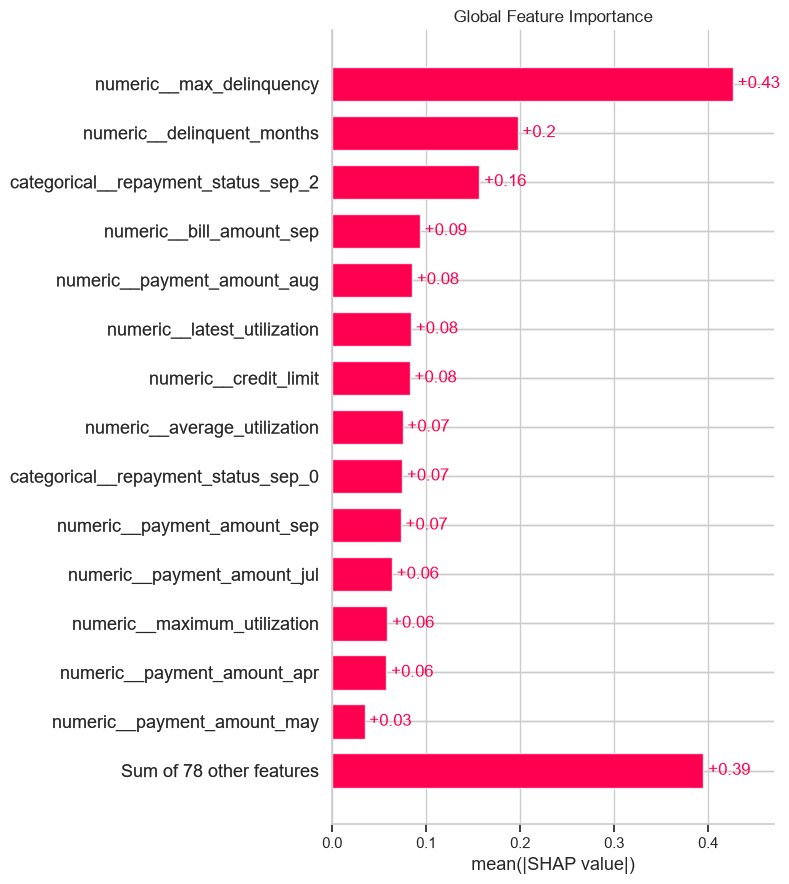

In [52]:
Path("figures").mkdir(parents=True, exist_ok=True)

shap.plots.bar(
    corrected_shap_values,
    max_display=15,
    show=False
)
plt.title("Global Feature Importance")
plt.tight_layout()
plt.savefig(
    "figures/shap_global_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


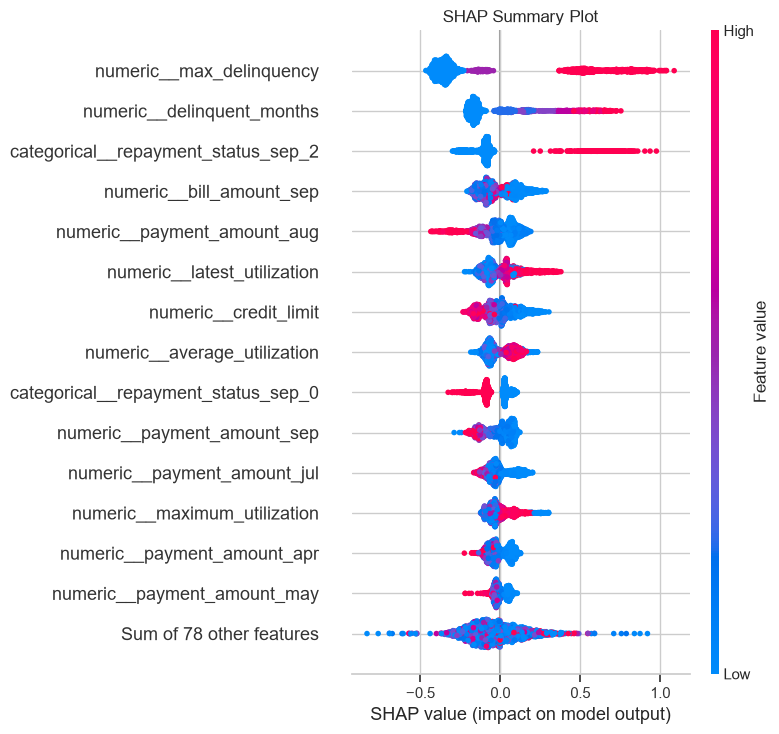

In [53]:
shap.plots.beeswarm(
    corrected_shap_values,
    max_display=15,
    show=False
)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.savefig(
    "figures/shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [54]:
shap_importance = (
    pd.DataFrame({
        "feature": shap_feature_names,
        "mean_absolute_shap": np.abs(
            corrected_shap_values.values
        ).mean(axis=0)
    })
    .sort_values(
        "mean_absolute_shap",
        ascending=False
    )
    .reset_index(drop=True)
)

display(shap_importance.head(15).round(4))


,feature,mean_absolute_shap
0,numeric__max_delinquency,0.4264
1,numeric__delinquent_months,0.1973
2,categorical__repayment_status_sep_2,0.1566
3,numeric__bill_amount_sep,0.0934
4,numeric__payment_amount_aug,0.0849
5,numeric__latest_utilization,0.0839
6,numeric__credit_limit,0.0825
7,numeric__average_utilization,0.0749
8,categorical__repayment_status_sep_0,0.0744
9,numeric__payment_amount_sep,0.0729


**SHAP finding.** After preserving the sparse feature representation
used by the XGBoost pipeline, repayment behaviour became the dominant
source of model risk predictions.

Higher maximum delinquency, more delinquent months, a latest repayment
status of 2, and higher credit utilization increased predicted default
risk. Higher credit limits and payment amounts generally reduced
predicted risk.

The rare Other/Unknown education category had a strong protective
effect for the small number of customers belonging to that category,
but its overall importance was low. This association should not be
interpreted causally.

### 9.2 Rare-Category Stability Check

The `Other/Unknown` education category is inspected separately because it is
rare. This check prevents a large per-customer SHAP value in a small subgroup
from being mistaken for high global importance.


In [55]:
train_education = X_train[
    ["education"]
].copy()

train_education["default_next_month"] = (
    y_train
)

train_education_summary = (
    train_education
    .groupby("education")[
        "default_next_month"
    ]
    .agg(
        train_count="size",
        train_default_count="sum",
        train_default_rate="mean"
    )
    .reset_index()
)

train_education_summary["train_share"] = (
    train_education_summary["train_count"]
    / len(train_education)
)


test_education = X_test[
    ["education"]
].copy()

test_education["default_next_month"] = (
    y_test
)

test_education_summary = (
    test_education
    .groupby("education")[
        "default_next_month"
    ]
    .agg(
        test_count="size",
        test_default_count="sum",
        test_default_rate="mean"
    )
    .reset_index()
)

test_education_summary["test_share"] = (
    test_education_summary["test_count"]
    / len(test_education)
)

education_audit = (
    train_education_summary
    .merge(
        test_education_summary,
        on="education",
        how="outer"
    )
)

display(education_audit.round(4))

,education,train_count,train_default_count,train_default_rate,train_share,test_count,test_default_count,test_default_rate,test_share
0,1,8455,1631,0.1929,0.3523,2130,405,0.1901,0.3550
1,2,11256,2674,0.2376,0.4690,2774,656,0.2365,0.4623
2,3,3903,976,0.2501,0.1626,1014,261,0.2574,0.1690
3,4,386,28,0.0725,0.0161,82,5,0.0610,0.0137


In [56]:
education_4_index = np.where(
    shap_feature_names
    == "categorical__education_4"
)[0][0]

education_4_audit = pd.DataFrame({
    "education_4": plot_data[:, education_4_index],
    "shap_value": corrected_shap_values.values[
        :, education_4_index
    ]
})

education_4_shap_summary = (
    education_4_audit
    .groupby("education_4")
    .agg(
        sample_count=("shap_value", "size"),
        mean_shap_value=("shap_value", "mean"),
        mean_absolute_shap=(
            "shap_value",
            lambda values: np.abs(values).mean()
        )
    )
    .reset_index()
)

display(education_4_shap_summary.round(4))


,education_4,sample_count,mean_shap_value,mean_absolute_shap
0,0.0,1979,0.0059,0.0059
1,1.0,21,-0.4608,0.4608


The rare category can have a large local effect while contributing little to
population-level importance. Its association is descriptive, sample-specific,
and should not be interpreted causally.


## 10. Sensitive-Feature Analysis

A challenger model is evaluated without sex, education, and marital
status. This analysis tests whether potentially sensitive demographic
attributes provide material predictive value beyond behavioural and
financial variables.

In [57]:
from sklearn.base import clone

sensitive_features = [
    "sex",
    "education",
    "marital_status"
]

restricted_categorical_features = [
    column
    for column in categorical_features
    if column not in sensitive_features
]

restricted_numeric_features = [
    column
    for column in numeric_features
    if column not in sensitive_features
]

print(
    "移除后的类别变量：",
    len(restricted_categorical_features)
)

print(
    "移除后的数值变量：",
    len(restricted_numeric_features)
)

移除后的类别变量： 6
移除后的数值变量： 19


In [58]:
restricted_preprocessor = ColumnTransformer(
    [
        (
            "numeric",
            "passthrough",
            restricted_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            restricted_categorical_features
        )
    ],
    sparse_threshold=1.0
)

# 复制最佳XGBoost的参数，但重新训练
restricted_xgb = clone(final_xgb)

restricted_model = Pipeline([
    (
        "preprocessor",
        restricted_preprocessor
    ),
    (
        "model",
        restricted_xgb
    )
])

In [59]:
restricted_cv_results = cross_validate(
    restricted_model,
    X_train_fe,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [60]:
sensitive_feature_comparison = pd.DataFrame({
    "Full Model": [
        tuned_xgb_cv_results[
            f"test_{metric}"
        ].mean()
        for metric in scoring
    ],
    "Without Demographics": [
        restricted_cv_results[
            f"test_{metric}"
        ].mean()
        for metric in scoring
    ]
}, index=scoring.keys())

sensitive_feature_comparison["Difference"] = (
    sensitive_feature_comparison[
        "Without Demographics"
    ]
    - sensitive_feature_comparison[
        "Full Model"
    ]
)

display(
    sensitive_feature_comparison.round(4)
)

,Full Model,Without Demographics,Difference
roc_auc,0.7878,0.7865,-0.0013
pr_auc,0.5656,0.5629,-0.0027
accuracy,0.8221,0.8220,-0.0001
balanced_accuracy,0.6608,0.6610,0.0003
precision,0.6791,0.6779,-0.0012
recall,0.3714,0.3724,0.0009


**Sensitive-feature analysis.** Removing sex, education, and marital
status reduced cross-validated ROC-AUC by only 0.0013 and PR-AUC by
0.0027. Balanced accuracy and recall remained effectively unchanged.

These demographic variables therefore provided little incremental
predictive value beyond repayment behaviour and financial variables.
For a production setting, the restricted model would be preferable
from a governance perspective, subject to validation on a new
independent holdout sample.

The reported test-set results in this notebook correspond to the full
model and are not attributed to the restricted challenger model.

### 10.1 Subgroup Performance Audit

Model outcomes are compared across demographic subgroups using the
pre-selected 0.19 threshold. Differences are reported descriptively
and are not interpreted as evidence of discrimination or causality.

In [61]:
def calculate_subgroup_metrics(
    feature_data,
    y_true,
    predictions,
    group_column
):
    audit_data = pd.DataFrame({
        group_column: (
            feature_data[group_column]
            .to_numpy()
        ),
        "actual": y_true.to_numpy(),
        "predicted": predictions
    })

    rows = []

    for group_value, group_data in audit_data.groupby(
        group_column
    ):
        tn, fp, fn, tp = confusion_matrix(
            group_data["actual"],
            group_data["predicted"],
            labels=[0, 1]
        ).ravel()

        rows.append({
            group_column: group_value,
            "customer_count": len(group_data),
            "observed_default_rate": (
                group_data["actual"].mean()
            ),
            "high_risk_rate": (
                group_data["predicted"].mean()
            ),
            "recall_tpr": (
                tp / (tp + fn)
                if (tp + fn) > 0
                else np.nan
            ),
            "false_positive_rate": (
                fp / (fp + tn)
                if (fp + tn) > 0
                else np.nan
            ),
            "precision": (
                tp / (tp + fp)
                if (tp + fp) > 0
                else np.nan
            ),
            "false_negative_count": fn,
            "false_positive_count": fp
        })

    return pd.DataFrame(rows)

In [62]:
sex_audit = calculate_subgroup_metrics(
    X_test_fe,
    y_test,
    test_predictions_selected,
    "sex"
)
sex_audit.insert(
    1,
    "group_label",
    sex_audit["sex"].map({1: "Male", 2: "Female"})
)

education_audit_final = calculate_subgroup_metrics(
    X_test_fe,
    y_test,
    test_predictions_selected,
    "education"
)
education_audit_final.insert(
    1,
    "group_label",
    education_audit_final["education"].map({
        1: "Graduate school",
        2: "University",
        3: "High school",
        4: "Other/Unknown"
    })
)

marital_audit = calculate_subgroup_metrics(
    X_test_fe,
    y_test,
    test_predictions_selected,
    "marital_status"
)
marital_audit.insert(
    1,
    "group_label",
    marital_audit["marital_status"].map({
        1: "Married",
        2: "Single",
        3: "Other/Unknown"
    })
)

print("Sex audit")
display(sex_audit.round(4))

print("Education audit")
display(education_audit_final.round(4))

print("Marital-status audit")
display(marital_audit.round(4))


Sex audit


,sex,group_label,customer_count,observed_default_rate,high_risk_rate,recall_tpr,false_positive_rate,precision,false_negative_count,false_positive_count
0,1,Male,2402,0.2336,0.4009,0.7041,0.3085,0.4102,166,568
1,2,Female,3598,0.2129,0.3477,0.6697,0.2606,0.4101,253,738


Education audit


,education,group_label,customer_count,observed_default_rate,high_risk_rate,recall_tpr,false_positive_rate,precision,false_negative_count,false_positive_count
0,1,Graduate school,2130,0.1901,0.3056,0.6568,0.2232,0.4086,139,385
1,2,University,2774,0.2365,0.4077,0.7058,0.3154,0.4094,193,668
2,3,High school,1014,0.2574,0.4201,0.6782,0.3307,0.4155,84,249
3,4,Other/Unknown,82,0.0610,0.0732,0.4000,0.0519,0.3333,3,4


Marital-status audit


,marital_status,group_label,customer_count,observed_default_rate,high_risk_rate,recall_tpr,false_positive_rate,precision,false_negative_count,false_positive_count
0,1,Married,2767,0.2414,0.3806,0.6991,0.2792,0.4435,201,586
1,2,Single,3158,0.2049,0.3569,0.6692,0.2764,0.3842,214,694
2,3,Other/Unknown,75,0.1600,0.4533,0.6667,0.4127,0.2353,4,26


**Subgroup audit.** Precision was nearly identical across the two sex
groups, while true-positive rates differed by approximately 3.4
percentage points and false-positive rates by approximately 4.8
percentage points.

For the three sufficiently populated education groups, precision was
stable at approximately 41%, although false-positive rates varied from
22.32% to 33.07%. The Other/Unknown education group and the third
marital-status group were too small for reliable conclusions.

Because demographic attributes produced negligible improvements in
cross-validated performance, a model excluding these attributes is
recommended for future production consideration. Such a model would
require validation on a new independent holdout sample.

## 11. Limitations and Governance Considerations

- The dataset represents Taiwanese credit-card customers from 2005 and may not
  reflect current portfolios, policies, macroeconomic conditions, or markets.
- The random holdout split does not test temporal drift. A production model
  would require out-of-time and external validation.
- The 5:1 cost ratio is illustrative; real thresholds require validated loss
  severity, investigation capacity, and policy constraints.
- Subgroup findings are descriptive. Small groups have high statistical
  uncertainty, and no causal or legal fairness conclusion is claimed.
- The full benchmark uses demographic variables. The restricted challenger
  produced nearly identical development performance and is preferable for
  future governance review, subject to independent validation.


## 12. Export Reproducible Artifacts

The final fitted pipeline, model metadata, validation tables, dashboard data,
and SHAP figures are saved below. These files support the accompanying README,
model card, and interactive dashboard.


In [63]:
from pathlib import Path
import json
import platform
import joblib
import sklearn
import xgboost

Path("models").mkdir(parents=True, exist_ok=True)
Path("reports/tables").mkdir(parents=True, exist_ok=True)
Path("figures").mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_model,
    "models/tuned_xgboost_full_model.joblib"
)

model_metadata = {
    "model_name": "Tuned XGBoost Full Benchmark",
    "data_source": "UCI Machine Learning Repository dataset 350",
    "target": "default_next_month",
    "train_rows": int(len(X_train_fe)),
    "test_rows": int(len(X_test_fe)),
    "random_state": 42,
    "selected_threshold": float(selected_threshold),
    "threshold_method": (
        "Minimum development OOF cost under a 5:1 "
        "false-negative to false-positive cost ratio"
    ),
    "false_negative_cost": 5,
    "false_positive_cost": 1,
    "test_roc_auc": float(test_roc_auc),
    "test_pr_auc": float(test_pr_auc),
    "test_ks": float(test_ks),
    "test_brier_score": float(test_brier),
    "test_binned_ece": float(ece),
    "brier_skill_score": float(brier_skill_score),
    "uses_demographic_features": True,
    "governance_recommendation": (
        "Validate the restricted challenger without sex, education, "
        "and marital status on a new independent holdout."
    ),
    "feature_columns": list(X_train_fe.columns),
    "package_versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "shap": shap.__version__
    }
}

with open(
    "models/model_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        model_metadata,
        file,
        ensure_ascii=False,
        indent=2
    )

print("最终模型与元数据已保存")


最终模型与元数据已保存


In [64]:
ranking_results.rename_axis("metric").to_csv(
    "reports/tables/test_ranking_metrics.csv"
)
test_threshold_comparison.rename_axis("operating_point").to_csv(
    "reports/tables/threshold_comparison.csv"
)
threshold_results.to_csv(
    "reports/tables/development_threshold_grid.csv",
    index=False
)
calibration_summary.to_csv(
    "reports/tables/calibration_summary.csv",
    index=False
)
model_comparison.to_csv(
    "reports/tables/logistic_feature_comparison.csv"
)
model_comparison_2.to_csv(
    "reports/tables/model_comparison.csv"
)
tuning_comparison.to_csv(
    "reports/tables/xgboost_tuning_comparison.csv"
)
sensitive_feature_comparison.to_csv(
    "reports/tables/sensitive_feature_analysis.csv"
)
shap_importance.to_csv(
    "reports/tables/shap_feature_importance.csv",
    index=False
)
sex_audit.to_csv(
    "reports/tables/sex_subgroup_audit.csv",
    index=False
)
education_audit_final.to_csv(
    "reports/tables/education_subgroup_audit.csv",
    index=False
)
marital_audit.to_csv(
    "reports/tables/marital_subgroup_audit.csv",
    index=False
)

dashboard_data = pd.DataFrame({
    "actual_default": y_test.to_numpy(),
    "predicted_probability": test_probabilities
})
dashboard_data.to_csv(
    "reports/tables/test_predictions.csv",
    index=False
)

print("验证表格与Dashboard数据已保存")
print("Dashboard数据形状：", dashboard_data.shape)


验证表格与Dashboard数据已保存
Dashboard数据形状： (6000, 2)


In [65]:
expected_artifacts = [
    "models/tuned_xgboost_full_model.joblib",
    "models/model_metadata.json",
    "reports/tables/test_ranking_metrics.csv",
    "reports/tables/threshold_comparison.csv",
    "reports/tables/test_predictions.csv",
    "reports/tables/shap_feature_importance.csv",
    "reports/tables/sensitive_feature_analysis.csv",
    "figures/calibration_plot.png",
    "figures/shap_global_importance.png",
    "figures/shap_summary.png"
]

artifact_check = pd.DataFrame({
    "artifact": expected_artifacts,
    "exists": [Path(path).exists() for path in expected_artifacts],
    "size_kb": [
        round(Path(path).stat().st_size / 1024, 1)
        if Path(path).exists()
        else np.nan
        for path in expected_artifacts
    ]
})

display(artifact_check)
assert artifact_check["exists"].all()
print("全部核心项目文件已成功导出")


,artifact,exists,size_kb
0,models/tuned_xgboost_full_model.joblib,True,732.8
1,models/model_metadata.json,True,1.7
2,reports/tables/test_ranking_metrics.csv,True,0.1
3,reports/tables/threshold_comparison.csv,True,0.4
4,reports/tables/test_predictions.csv,True,81.8
5,reports/tables/shap_feature_importance.csv,True,3.9
6,reports/tables/sensitive_feature_analysis.csv,True,0.5
7,figures/calibration_plot.png,True,84.7
8,figures/shap_global_importance.png,True,144.5
9,figures/shap_summary.png,True,241.2


全部核心项目文件已成功导出
